<a href="https://colab.research.google.com/github/meky06/Arsonists-Project/blob/Notebook/Arsonists.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import gdown
import geopandas as gpd

gdown.download(id="1xl7zlniPNN-EjFvUGkHuCOMdpsXeTvQm", output="spain_provinces.gpkg")
spain = gpd.read_file("spain_provinces.gpkg")
len(spain)

Downloading...
From: https://drive.google.com/uc?id=1xl7zlniPNN-EjFvUGkHuCOMdpsXeTvQm
To: /content/spain_provinces.gpkg
100%|██████████| 410k/410k [00:00<00:00, 75.6MB/s]


52

EPSG:4326


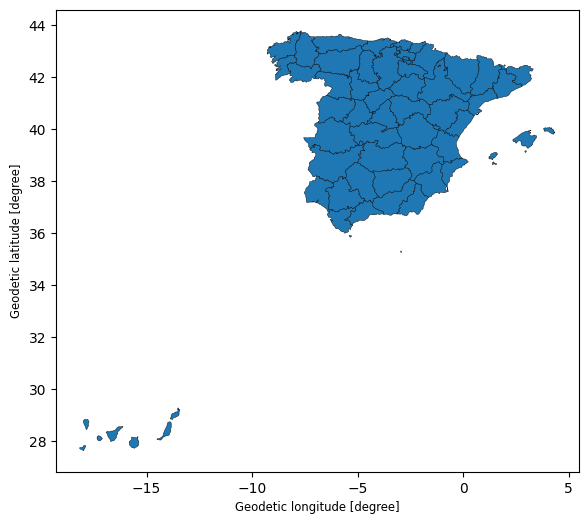

In [ ]:
spain = spain.to_crs("EPSG:4326")
spain.plot(figsize=(8, 6), edgecolor="black", linewidth=0.3)
print(spain.crs)

In [ ]:
import gdown
gdown.download(id="1lT83-mn2z05yxkGHl-E3TWqwraxBnsU6", output="modis_spain.csv")

Downloading...
From: https://drive.google.com/uc?id=1lT83-mn2z05yxkGHl-E3TWqwraxBnsU6
To: /content/modis_spain.csv
100%|██████████| 9.01M/9.01M [00:00<00:00, 25.0MB/s]


'modis_spain.csv'

In [36]:
import pandas as pd
df = pd.read_csv("modis_spain.csv")

print(df.shape)
print(df.columns.tolist())
df.info()
print(df.head(3).to_string())
print(df.isna().sum())
print("duplicates:", df.duplicated().sum())

(114797, 15)
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114797 entries, 0 to 114796
Data columns (total 15 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   latitude    114797 non-null  float64
 1   longitude   114797 non-null  float64
 2   brightness  114797 non-null  float64
 3   scan        114797 non-null  float64
 4   track       114797 non-null  float64
 5   acq_date    114797 non-null  object 
 6   acq_time    114797 non-null  int64  
 7   satellite   114797 non-null  object 
 8   instrument  114797 non-null  object 
 9   confidence  114797 non-null  int64  
 10  version     114797 non-null  float64
 11  bright_t31  114797 non-null  float64
 12  frp         114797 non-null  float64
 13  daynight    114797 non-null  object 
 14  type        114797 non-nu

In [37]:
# standardize column names
df.columns = df.columns.str.strip().str.lower()

# remove duplicates
df = df.drop_duplicates()

# fix dates
df["acq_date"] = pd.to_datetime(df["acq_date"], errors="coerce")

# drop rows missing essentials
df = df.dropna(subset=["latitude", "longitude", "acq_date"])

# valid coordinates
df = df[df["latitude"].between(-90, 90) & df["longitude"].between(-180, 180)]

# physically invalid values
df = df[(df["brightness"] > 0) & (df["frp"] >= 0)]

In [38]:
print(df["confidence"].unique()[:10])

[45  0 79 58 54 55 52 76 63 64]


In [39]:
if "type" in df.columns:
    df = df[df["type"] == 0]

In [40]:
df["year"] = df["acq_date"].dt.year
df["month"] = df["acq_date"].dt.month

In [ ]:
print(df.shape)
print(df.isna().sum())

df.to_csv("modis_spain_clean.csv", index=False)

(104608, 17)
latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_t31    0
frp           0
daynight      0
type          0
year          0
month         0
dtype: int64


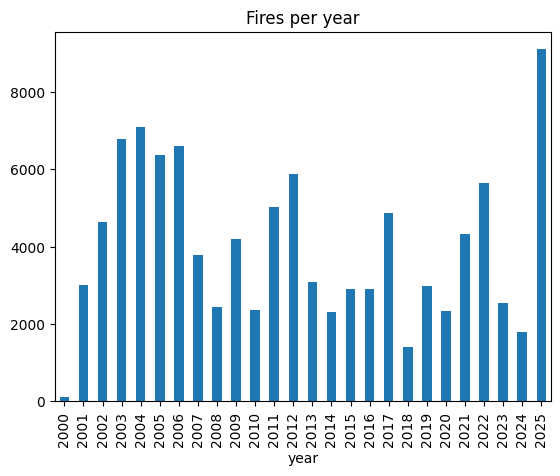

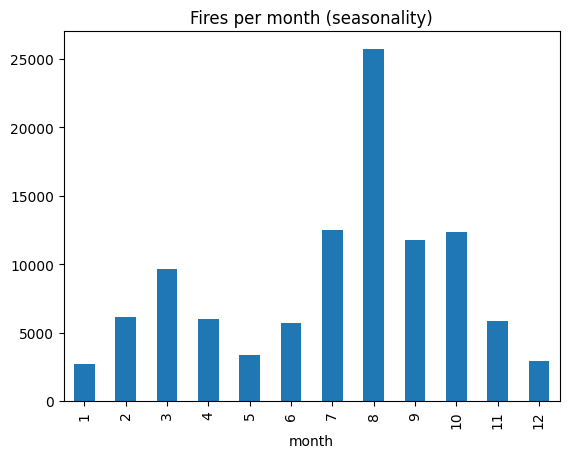

In [ ]:
import matplotlib.pyplot as plt

df.groupby("year").size().plot(kind="bar", title="Fires per year")
plt.show()

df.groupby("month").size().plot(kind="bar", title="Fires per month (seasonality)")
plt.show()

daynight
D    73946
N    30662
Name: count, dtype: int64


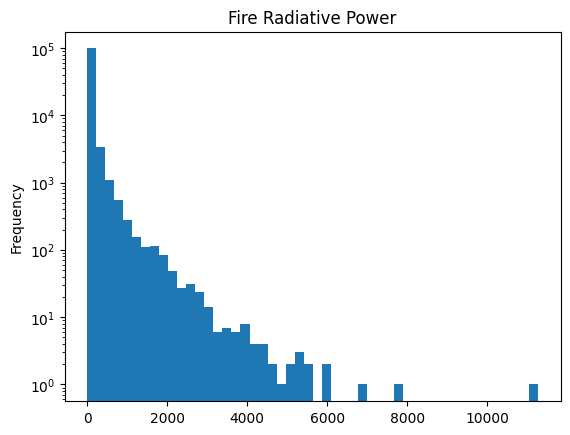

In [ ]:
print(df["daynight"].value_counts())

df["frp"].plot(kind="hist", bins=50, log=True, title="Fire Radiative Power")
plt.show()

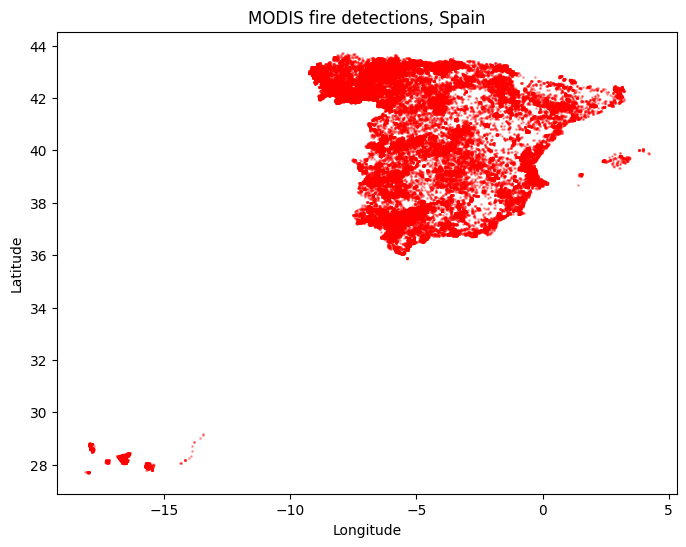

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(df["longitude"], df["latitude"], s=1, alpha=0.3, c="red")
plt.title("MODIS fire detections, Spain")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()

In [41]:
monthly = df.groupby(["year", "month"]).agg(
    fire_count=("frp", "size"),
    total_frp=("frp", "sum"),
    mean_brightness=("brightness", "mean")
).reset_index()
monthly.head()

,year,month,fire_count,total_frp,mean_brightness
0,2000,11,92,1436.4,308.952174
1,2000,12,23,485.5,313.343478
2,2001,1,9,181.8,309.544444
3,2001,2,106,1841.8,308.291509
4,2001,3,61,772.0,309.763934


In [ ]:
gdown.download(id="1Il1W2i-GJ4ceOkC_UNA71lS6XZNyPooH", output="viirs_noaa20_spain.csv")
gdown.download(id="1JHnlTqU7F4g60QSlT_lVISKQBV6rXaeA", output="viirs_snpp_spain.csv")
df_viirs_noaa20 = pd.read_csv("viirs_noaa20_spain.csv")
df_viirs_snpp = pd.read_csv("viirs_snpp_spain.csv")

Downloading...
From: https://drive.google.com/uc?id=1Il1W2i-GJ4ceOkC_UNA71lS6XZNyPooH
To: /content/viirs_noaa20_spain.csv
100%|██████████| 11.0M/11.0M [00:00<00:00, 317MB/s]
Downloading...
From: https://drive.google.com/uc?id=1JHnlTqU7F4g60QSlT_lVISKQBV6rXaeA
To: /content/viirs_snpp_spain.csv
100%|██████████| 18.6M/18.6M [00:00<00:00, 32.6MB/s]


In [ ]:
print(df_viirs_noaa20.shape)
print(df_viirs_noaa20.columns.tolist())
df_viirs_noaa20.info()
print(df_viirs_noaa20.head(3).to_string())
print(df_viirs_noaa20.isna().sum())
print("duplicates:", df_viirs_noaa20.duplicated().sum())

(137480, 15)
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137480 entries, 0 to 137479
Data columns (total 15 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   latitude    137480 non-null  float64
 1   longitude   137480 non-null  float64
 2   brightness  137480 non-null  float64
 3   scan        137480 non-null  float64
 4   track       137480 non-null  float64
 5   acq_date    137480 non-null  object 
 6   acq_time    137480 non-null  int64  
 7   satellite   137480 non-null  object 
 8   instrument  137480 non-null  object 
 9   confidence  137480 non-null  object 
 10  version     137480 non-null  int64  
 11  bright_t31  137480 non-null  float64
 12  frp         137480 non-null  float64
 13  daynight    137480 non-null  object 
 14  type        137480 non-nu

In [ ]:
print(df_viirs_snpp.shape)
print(df_viirs_snpp.columns.tolist())
df_viirs_snpp.info()
print(df_viirs_snpp.head(3).to_string())
print(df_viirs_snpp.isna().sum())
print("duplicates:", df_viirs_snpp.duplicated().sum())

(231716, 15)
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231716 entries, 0 to 231715
Data columns (total 15 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   latitude    231716 non-null  float64
 1   longitude   231716 non-null  float64
 2   brightness  231716 non-null  float64
 3   scan        231716 non-null  float64
 4   track       231716 non-null  float64
 5   acq_date    231716 non-null  object 
 6   acq_time    231716 non-null  int64  
 7   satellite   231716 non-null  object 
 8   instrument  231716 non-null  object 
 9   confidence  231716 non-null  object 
 10  version     231716 non-null  int64  
 11  bright_t31  231716 non-null  float64
 12  frp         231716 non-null  float64
 13  daynight    231716 non-null  object 
 14  type        231716 non-nu

In [ ]:
# standardize column names
df_viirs_noaa20.columns = df_viirs_noaa20.columns.str.strip().str.lower()

# remove duplicates
df_viirs_noaa20 = df_viirs_noaa20.drop_duplicates()

# fix dates
df_viirs_noaa20["acq_date"] = pd.to_datetime(df_viirs_noaa20["acq_date"], errors="coerce")

# drop rows missing essentials
df_viirs_noaa20 = df_viirs_noaa20.dropna(subset=["latitude", "longitude", "acq_date"])

# valid coordinates
df_viirs_noaa20 = df_viirs_noaa20[df_viirs_noaa20["latitude"].between(-90, 90) & df_viirs_noaa20["longitude"].between(-180, 180)]

# physically invalid values
df_viirs_noaa20 = df_viirs_noaa20[(df_viirs_noaa20["brightness"] > 0) & (df_viirs_noaa20["frp"] >= 0)]

In [ ]:
if "type" in df_viirs_noaa20.columns:
    df_viirs_noaa20 = df_viirs_noaa20[df_viirs_noaa20["type"] == 0]

In [ ]:
df_viirs_noaa20["year"] = df_viirs_noaa20["acq_date"].dt.year
df_viirs_noaa20["month"] = df_viirs_noaa20["acq_date"].dt.month

In [ ]:
print(df_viirs_noaa20.shape)
print(df_viirs_noaa20.isna().sum())

df_viirs_noaa20.to_csv("modis_spain_clean.csv", index=False)

(107399, 17)
latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_t31    0
frp           0
daynight      0
type          0
year          0
month         0
dtype: int64


In [ ]:
# standardize column names
df_viirs_snpp.columns = df_viirs_snpp.columns.str.strip().str.lower()

# remove duplicates
df_viirs_snpp = df_viirs_snpp.drop_duplicates()

# fix dates
df_viirs_snpp["acq_date"] = pd.to_datetime(df_viirs_snpp["acq_date"], errors="coerce")

# drop rows missing essentials
df_viirs_snpp = df_viirs_snpp.dropna(subset=["latitude", "longitude", "acq_date"])

# valid coordinates
df_viirs_snpp = df_viirs_snpp[df_viirs_snpp["latitude"].between(-90, 90) & df_viirs_snpp["longitude"].between(-180, 180)]

# physically invalid values
df_viirs_snpp = df_viirs_snpp[(df_viirs_snpp["brightness"] > 0) & (df_viirs_snpp["frp"] >= 0)]

In [ ]:
if "type" in df_viirs_snpp.columns:
    df_viirs_snpp = df_viirs_snpp[df_viirs_snpp["type"] == 0]

In [ ]:
df_viirs_snpp["year"] = df_viirs_snpp["acq_date"].dt.year
df_viirs_snpp["month"] = df_viirs_snpp["acq_date"].dt.month

In [ ]:
print(df_viirs_snpp.shape)
print(df_viirs_snpp.isna().sum())

df_viirs_snpp.to_csv("modis_spain_clean.csv", index=False)

(175652, 17)
latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_t31    0
frp           0
daynight      0
type          0
year          0
month         0
dtype: int64


In [42]:
for name, d in [("modis", df), ("snpp", df_viirs_snpp), ("noaa20", df_viirs_noaa20)]:
    print(name, len(d))
    print(list(d.columns))
    print(d["confidence"].unique()[:10])
    print(d["satellite"].unique())
    print(d["acq_date"].min(), d["acq_date"].max())
    print()

modis 104608
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'year', 'month']
[ 0 79 58 54 55 52 76 63 64 59]
['Terra' 'Aqua']
2000-11-01 00:00:00 2025-12-27 00:00:00

snpp 175652
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'year', 'month']
['n' 'h' 'l']
['SNPP']
2012-01-20 00:00:00 2025-12-31 00:00:00

noaa20 107399
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'year', 'month']
['n' 'l' 'h']
['N20']
2018-04-01 00:00:00 2025-12-31 00:00:00



In [ ]:
import os, glob
print(os.getcwd())
print(os.listdir("."))
print(glob.glob("/content/**/*.parquet", recursive=True))

/content
['.config', 'modis_spain_clean.csv', 'spain_provinces.gpkg', 'viirs_noaa20_spain.csv', 'drive', 'modis_spain.csv', 'viirs_snpp_spain.csv', 'sample_data']
[]


In [43]:
import pandas as pd

keep = ["acq_date", "acq_time", "latitude", "longitude", "frp",
        "daynight", "satellite", "confidence"]

def to_common(d, sensor_name, viirs):
    out = d[keep].copy()
    out = out.rename(columns={"acq_date": "date", "latitude": "lat",
                              "longitude": "lon"})
    out["sensor"] = sensor_name
    if viirs:
        out["confidence_std"] = out["confidence"].map({"l": 0, "n": 1, "h": 2})
    else:
        out["confidence_std"] = out["confidence"].astype(float)
    return out.drop(columns="confidence")

all_hotspots = pd.concat([
    to_common(df, "MODIS", viirs=False),
    to_common(df_viirs_snpp, "VIIRS_SNPP", viirs=True),
    to_common(df_viirs_noaa20, "VIIRS_NOAA20", viirs=True),
], ignore_index=True)

print(all_hotspots.shape)
print(all_hotspots.groupby("sensor").size())
print(all_hotspots.isna().sum())

(387659, 9)
sensor
MODIS           104608
VIIRS_NOAA20    107399
VIIRS_SNPP      175652
dtype: int64
date              0
acq_time          0
lat               0
lon               0
frp               0
daynight          0
satellite         0
sensor            0
confidence_std    0
dtype: int64


In [44]:

is_modis = all_hotspots["sensor"] == "MODIS"

keep_modis = is_modis & (all_hotspots["confidence_std"] >= 30)
keep_viirs = ~is_modis & (all_hotspots["confidence_std"] >= 1)

filtered = all_hotspots[keep_modis | keep_viirs].copy()


before = all_hotspots.groupby("sensor").size()
after = filtered.groupby("sensor").size()

summary = pd.DataFrame({"before": before, "after": after})
summary["removed"] = summary["before"] - summary["after"]
summary["removed_%"] = (summary["removed"] / summary["before"] * 100).round(1)
print(summary)
print("total:", len(all_hotspots), "->", len(filtered))

              before   after  removed  removed_%
sensor                                          
MODIS         104608  100225     4383        4.2
VIIRS_NOAA20  107399  101150     6249        5.8
VIIRS_SNPP    175652  165630    10022        5.7
total: 387659 -> 367005


In [46]:
print(spain.columns)
print(len(spain))

Index(['featurecla', 'scalerank', 'adm1_code', 'diss_me', 'iso_3166_2',
       'wikipedia', 'iso_a2', 'adm0_sr', 'name', 'name_alt',
       ...
       'FCLASS_ID', 'FCLASS_PL', 'FCLASS_GR', 'FCLASS_IT', 'FCLASS_NL',
       'FCLASS_SE', 'FCLASS_BD', 'FCLASS_UA', 'FCLASS_TLC', 'geometry'],
      dtype='object', length=122)
52


In [48]:
import geopandas as gpd

provinces = spain[["name", "geometry"]].rename(columns={"name": "province"})


points = gpd.GeoDataFrame(
    filtered,
    geometry=gpd.points_from_xy(filtered["lon"], filtered["lat"]),
    crs="EPSG:4326",
)

joined = gpd.sjoin(points, provinces, how="inner", predicate="within")
joined = joined.drop(columns=["geometry", "index_right"])

print("before:", len(filtered), " after:", len(joined))
print(joined.groupby("sensor").size())
print(joined["province"].nunique(), "provinces found")
print(joined["province"].value_counts().head(10))

before: 367005  after: 367005
sensor
MODIS           100225
VIIRS_NOAA20    101150
VIIRS_SNPP      165630
dtype: int64
52 provinces found
province
Santa Cruz de Tenerife    36692
Orense                    32775
León                      31478
Asturias                  25607
Badajoz                   16556
Sevilla                   16281
Cáceres                   16254
Zamora                    13422
Cantabria                 12729
Lugo                       9225
Name: count, dtype: int64


In [49]:
tenerife = joined[joined["province"] == "Santa Cruz de Tenerife"]
print(tenerife.groupby(tenerife["date"].dt.year).size())

date
2002        1
2003        4
2004        2
2005       36
2006       29
2007      170
2008       14
2009       38
2010       13
2011        9
2012     1317
2013       10
2014       14
2015       23
2016      286
2017       18
2018      116
2019       35
2020      198
2021    28392
2022     3318
2023     2503
2024       82
2025       64
dtype: int64


In [50]:
v = tenerife[tenerife["date"].dt.year == 2021]
print(v[["lat", "lon"]].describe())

                lat           lon
count  28392.000000  28392.000000
mean      28.609867    -17.861456
std        0.056684      0.185670
min       27.725620    -18.150250
25%       28.608960    -17.904193
50%       28.617325    -17.887650
75%       28.625740    -17.871300
max       28.814250    -16.301540


In [51]:
in_box = (
    joined["lat"].between(28.52, 28.70) &
    joined["lon"].between(-17.97, -17.82)
)

print(joined[in_box].groupby(joined["date"].dt.year).size())

date
2005        1
2009        8
2012      131
2016      216
2018        2
2020        3
2021    27593
2022     2811
2023       23
2024        4
dtype: int64


In [52]:
box = joined[in_box & (joined["date"] >= "2021-09-01") & (joined["date"] < "2023-01-01")]
print(box.groupby(box["date"].dt.to_period("M")).size())

date
2021-09     3424
2021-10    12615
2021-11     7395
2021-12     4133
2022-01     1337
2022-02      605
2022-03      363
2022-04      186
2022-05      128
2022-06       77
2022-07       27
2022-08       11
2022-09       31
2022-10       15
2022-11       16
2022-12       15
Freq: M, dtype: int64


In [53]:
in_box = (
    joined["lat"].between(28.52, 28.70) &
    joined["lon"].between(-17.97, -17.82)
)
in_period = joined["date"].between("2021-09-19", "2022-06-30")

joined["volcanic"] = in_box & in_period

print(joined["volcanic"].sum(), "points flagged")
print(joined.groupby("volcanic").size())
print(joined[joined["province"] == "Santa Cruz de Tenerife"].groupby("volcanic").size())

30263 points flagged
volcanic
False    336742
True      30263
dtype: int64
volcanic
False     6429
True     30263
dtype: int64


In [54]:
check = joined[~joined["volcanic"]].copy()

# round coordinates to 2 decimals, which makes squares of about 1 km
check["cell_lat"] = check["lat"].round(2)
check["cell_lon"] = check["lon"].round(2)

cells = check.groupby(["cell_lat", "cell_lon"]).agg(
    years=("date", lambda s: s.dt.year.nunique()),
    days=("date", "nunique"),
    province=("province", "first"),
).sort_values("years", ascending=False)

print(cells.head(15))
print((cells["years"] >= 10).sum(), "squares with detections in 10+ different years")

                   years  days     province
cell_lat cell_lon                          
38.61    -0.59        24   233     Alicante
41.18     1.24        23   103    Tarragona
38.67    -4.05        22   255  Ciudad Real
39.49    -6.42        22    51      Cáceres
39.02    -1.88        22   108     Albacete
40.25    -3.48        22    68       Madrid
39.62    -3.36        21    44       Toledo
39.01    -1.88        21    61     Albacete
38.61    -0.60        20    65     Alicante
38.67    -4.04        20    58  Ciudad Real
39.48    -0.58        19    28     Valencia
38.67    -4.06        19    84  Ciudad Real
38.68    -4.05        19   103  Ciudad Real
38.62    -0.59        19    57     Alicante
         -1.07        19    90       Murcia
265 squares with detections in 10+ different years


In [55]:
rows = check.groupby(["cell_lat", "cell_lon"]).size().rename("rows")
cells = cells.join(rows)
cells["days_per_year"] = (cells["days"] / cells["years"]).round(1)

for y in [10, 15, 18, 20]:
    sel = cells[cells["years"] >= y]
    print(f"{y}+ years: {len(sel)} squares, {sel['rows'].sum()} rows")

print(cells[cells["years"] >= 15].sort_values("days_per_year", ascending=False).head(15))

10+ years: 265 squares, 14335 rows
15+ years: 46 squares, 3908 rows
18+ years: 21 squares, 2161 rows
20+ years: 10 squares, 1243 rows
                   years  days     province  rows  days_per_year
cell_lat cell_lon                                               
41.18     1.23        15   212    Tarragona   542           14.1
38.67    -4.05        22   255  Ciudad Real   364           11.6
38.61    -0.59        24   233     Alicante   239            9.7
43.54    -5.83        16   125     Asturias   135            7.8
38.28    -1.60        15    93       Murcia   159            6.2
39.02    -1.89        18   110     Albacete   112            6.1
38.68    -4.05        19   103  Ciudad Real   153            5.4
39.02    -1.88        22   108     Albacete   108            4.9
43.35    -8.45        15    73    La Coruña    89            4.9
40.24    -3.48        16    77       Madrid    79            4.8
38.62    -1.07        19    90       Murcia    92            4.7
43.54    -5.84       

In [56]:
joined["cell_lat"] = joined["lat"].round(2)
joined["cell_lon"] = joined["lon"].round(2)

static_cells = cells[cells["years"] >= 15].reset_index()[["cell_lat", "cell_lon"]]
static_cells["static_source"] = True

joined = joined.merge(static_cells, on=["cell_lat", "cell_lon"], how="left")
joined["static_source"] = joined["static_source"].eq(True)

print(len(joined), "rows (should still be 367005)")
print(joined["static_source"].sum(), "points flagged as static")
print(joined.groupby(["volcanic", "static_source"]).size())

367005 rows (should still be 367005)
3908 points flagged as static
volcanic  static_source
False     False            332834
          True               3908
True      False             30263
dtype: int64


In [57]:
rename = {
    "Orense": "Ourense",
    "Lérida": "Lleida",
    "Gerona": "Girona",
    "La Coruña": "A Coruña",
}
joined["province"] = joined["province"].replace(rename)

print(sorted(joined["province"].unique()))

['A Coruña', 'Albacete', 'Alicante', 'Almería', 'Asturias', 'Badajoz', 'Baleares', 'Barcelona', 'Bizkaia', 'Burgos', 'Cantabria', 'Castellón', 'Ceuta', 'Ciudad Real', 'Cuenca', 'Cáceres', 'Cádiz', 'Córdoba', 'Gipuzkoa', 'Girona', 'Granada', 'Guadalajara', 'Huelva', 'Huesca', 'Jaén', 'La Rioja', 'Las Palmas', 'León', 'Lleida', 'Lugo', 'Madrid', 'Melilla', 'Murcia', 'Málaga', 'Navarra', 'Ourense', 'Palencia', 'Pontevedra', 'Salamanca', 'Santa Cruz de Tenerife', 'Segovia', 'Sevilla', 'Soria', 'Tarragona', 'Teruel', 'Toledo', 'Valencia', 'Valladolid', 'Zamora', 'Zaragoza', 'Álava', 'Ávila']


In [58]:
out_cols = ["date", "acq_time", "lat", "lon", "frp", "daynight",
            "satellite", "sensor", "confidence_std", "province",
            "volcanic", "static_source", "cell_lat", "cell_lon"]

joined[out_cols].to_parquet(f"{data}/clean/clean_hotspots.parquet", index=False)

summary = pd.DataFrame({
    "step": ["Raw rows (3 sensors, after basic cleaning)",
             "After confidence filter",
             "After province join (all inside Spain)",
             "Flagged: volcanic (La Palma 2021-22)",
             "Flagged: static heat sources",
             "Usable for harmonization"],
    "rows": [387659, 367005, 367005, 30263, 3908, 332834],
})
summary.to_csv(f"{data}/clean/data_quality_summary.csv", index=False)
print(summary)

                                         step    rows
0  Raw rows (3 sensors, after basic cleaning)  387659
1                     After confidence filter  367005
2      After province join (all inside Spain)  367005
3        Flagged: volcanic (La Palma 2021-22)   30263
4                Flagged: static heat sources    3908
5                    Usable for harmonization  332834


In [59]:
check = pd.read_parquet(f"{data}/clean/clean_hotspots.parquet")
print(check.shape)   # expect (367005, 14)

(367005, 14)


# **Harmonization**

In [60]:
import pandas as pd

hot = pd.read_parquet(f"{data}/clean/clean_hotspots.parquet")

# step 1: keep only rows that are not volcanic and not static sources
usable = hot[~hot["volcanic"] & ~hot["static_source"]].copy()
print(len(usable), "rows (expect 332834)")

# step 2: give each point a square ID from its rounded coordinates
lat_i = (usable["cell_lat"] * 100).round().astype(int)
lon_i = (usable["cell_lon"] * 100).round().astype(int)
usable["cell_id"] = lat_i.astype(str) + "_" + lon_i.astype(str)

print(usable["cell_id"].nunique(), "different squares")

# step 3 preview: points vs. squares-with-a-detection per day, per sensor
points = usable.groupby("sensor").size()
cell_days = usable.drop_duplicates(["sensor", "date", "cell_id"]).groupby("sensor").size()

compare = pd.DataFrame({"points": points, "cell_days": cell_days})
compare["points_per_cell_day"] = (compare["points"] / compare["cell_days"]).round(2)
print(compare)

332834 rows (expect 332834)
97857 different squares
              points  cell_days  points_per_cell_day
sensor                                              
MODIS          97290      88257                 1.10
VIIRS_NOAA20   85523      46148                 1.85
VIIRS_SNPP    150021      84780                 1.77


In [61]:
# one row per satellite, day, square and province (this is the "count squares, not points" step)
cells = usable.drop_duplicates(["satellite", "date", "cell_id", "province"]).copy()
cells["year"] = cells["date"].dt.year
cells["month"] = cells["date"].dt.month

monthly = (cells.groupby(["province", "year", "month", "satellite"])
                .size().rename("cell_days").reset_index())

monthly.to_parquet(f"{data}/harmonized/monthly_counts_by_satellite.parquet", index=False)
print(monthly.shape)
print(monthly.groupby("satellite")["cell_days"].sum())

# Spain-wide monthly totals, then compare Aqua and Suomi VIIRS in the overlap
spain_m = (monthly.groupby(["year", "month", "satellite"])["cell_days"].sum()
                  .unstack("satellite"))
overlap = spain_m.loc[2012:2025, ["Aqua", "SNPP"]].dropna()
print(len(overlap), "months compared")
print("correlation:", overlap["Aqua"].corr(overlap["SNPP"]).round(3))
print("typical ratio SNPP / Aqua:", (overlap["SNPP"].sum() / overlap["Aqua"].sum()).round(2))

(24306, 5)
satellite
Aqua     42043
N20      46311
SNPP     85030
Terra    50389
Name: cell_days, dtype: int64
168 months compared
correlation: 0.963
typical ratio SNPP / Aqua: 3.89


In [63]:
import numpy as np

o = overlap.reset_index()   # year and month become normal columns

print("ratio by month of year:")
print((o.groupby("month")["SNPP"].sum() / o.groupby("month")["Aqua"].sum()).round(2))

print("ratio by year:")
print((o.groupby("year")["SNPP"].sum() / o.groupby("year")["Aqua"].sum()).round(2))

x = np.log(o["Aqua"] + 1)
y = np.log(o["SNPP"] + 1)
slope, intercept = np.polyfit(x, y, 1)
print("log-log fit: slope", round(slope, 2), "intercept", round(intercept, 2))

ratio by month of year:
month
1     3.76
2     4.18
3     4.48
4     5.20
5     5.98
6     4.27
7     3.12
8     2.71
9     4.15
10    5.38
11    4.98
12    4.15
dtype: float64
ratio by year:
year
2012    3.25
2013    4.44
2014    5.51
2015    4.73
2016    4.33
2017    4.06
2018    6.43
2019    4.75
2020    4.90
2021    4.32
2022    3.05
2023    4.22
2024    4.12
2025    2.60
dtype: float64
log-log fit: slope 0.68 intercept 2.99


In [64]:
o = overlap.reset_index()
o["lx"] = np.log(o["SNPP"] + 1)
o["ly"] = np.log(o["Aqua"] + 1)

rows = []
for yr in sorted(o["year"].unique()):
    train, test = o[o["year"] != yr], o[o["year"] == yr]
    b, a = np.polyfit(train["lx"], train["ly"], 1)
    pred = np.exp(a + b * test["lx"]) - 1
    err = (pred.sum() - test["Aqua"].sum()) / test["Aqua"].sum() * 100
    rows.append((yr, round(err, 1)))

print(pd.DataFrame(rows, columns=["held_out_year", "yearly_total_error_%"]))

    held_out_year  yearly_total_error_%
0            2012                 -21.2
1            2013                  -1.0
2            2014                  22.9
3            2015                   4.8
4            2016                  -4.1
5            2017                  -3.7
6            2018                  30.9
7            2019                   7.7
8            2020                   5.3
9            2021                  -9.4
10           2022                 -26.9
11           2023                  -8.5
12           2024                 -21.7
13           2025                 -28.0


In [65]:
o = overlap.reset_index()
o["lx"] = np.log(o["SNPP"] + 1)
o["ly"] = np.log(o["Aqua"] + 1)
o["season"] = np.where(o["month"].between(6, 9), "summer", "other")

rows = []
for yr in sorted(o["year"].unique()):
    train, test = o[o["year"] != yr], o[o["year"] == yr]
    pred_total = 0
    for s in ["summer", "other"]:
        tr, te = train[train["season"] == s], test[test["season"] == s]
        b, a = np.polyfit(tr["lx"], tr["ly"], 1)
        pred_total += (np.exp(a + b * te["lx"]) - 1).sum()
    err = (pred_total - test["Aqua"].sum()) / test["Aqua"].sum() * 100
    rows.append((yr, round(err, 1)))

res = pd.DataFrame(rows, columns=["held_out_year", "yearly_total_error_%"])
print(res)
print("mean absolute error:", res["yearly_total_error_%"].abs().mean().round(1))

    held_out_year  yearly_total_error_%
0            2012                 -22.7
1            2013                   1.2
2            2014                  12.8
3            2015                   4.8
4            2016                   3.5
5            2017                 -13.7
6            2018                  27.8
7            2019                  -1.5
8            2020                   5.6
9            2021                  -9.4
10           2022                  -4.5
11           2023                 -16.9
12           2024                 -25.3
13           2025                  58.9
mean absolute error: 14.9


In [66]:
idx = pd.MultiIndex.from_product([range(2012, 2026), range(1, 13)], names=["year", "month"])
aqua = cells[cells["satellite"] == "Aqua"].groupby(["year", "month"]).size().reindex(idx, fill_value=0)

rows = []
for t in [0, 2, 5, 10, 20]:
    s = usable[(usable["satellite"] == "SNPP") & (usable["frp"] >= t)]
    s = s.drop_duplicates(["date", "cell_id", "province"])
    snpp = (s.groupby([s["date"].dt.year.rename("year"), s["date"].dt.month.rename("month")])
              .size().reindex(idx, fill_value=0))
    d = pd.DataFrame({"Aqua": aqua, "SNPP": snpp}).reset_index()

    m = d.groupby("month")[["Aqua", "SNPP"]].sum()
    mr = m["SNPP"] / m["Aqua"]

    errs = []
    for yr in d["year"].unique():
        tr, te = d[d["year"] != yr], d[d["year"] == yr]
        k = tr["Aqua"].sum() / tr["SNPP"].sum()
        errs.append(abs(k * te["SNPP"].sum() - te["Aqua"].sum()) / te["Aqua"].sum() * 100)

    rows.append((t, round(d["SNPP"].sum() / d["Aqua"].sum(), 2),
                 round(d["Aqua"].corr(d["SNPP"]), 3),
                 round(mr.min(), 2), round(mr.max(), 2),
                 round(sum(errs) / len(errs), 1)))

print(pd.DataFrame(rows, columns=["frp_min", "overall_ratio", "corr",
                                  "lowest_month_ratio", "highest_month_ratio",
                                  "mean_abs_error_%"]))

   frp_min  overall_ratio   corr  lowest_month_ratio  highest_month_ratio  \
0        0           3.89  0.963                2.71                 5.98   
1        2           2.85  0.974                2.15                 4.20   
2        5           1.61  0.992                1.13                 2.00   
3       10           0.90  0.987                0.39                 1.17   
4       20           0.50  0.975                0.11                 0.77   

   mean_abs_error_%  
0              23.2  
1              18.6  
2               9.4  
3              11.7  
4              22.3  


In [67]:
def build(t):
    s = usable[(usable["satellite"] == "SNPP") & (usable["frp"] >= t)]
    s = s.drop_duplicates(["date", "cell_id", "province"])
    snpp = (s.groupby([s["date"].dt.year.rename("year"), s["date"].dt.month.rename("month")])
              .size().reindex(idx, fill_value=0))
    return pd.DataFrame({"Aqua": aqua, "SNPP": snpp}).reset_index()

def yearly_errors(d):
    out = {}
    for yr in d["year"].unique():
        tr, te = d[d["year"] != yr], d[d["year"] == yr]
        k = tr["Aqua"].sum() / tr["SNPP"].sum()
        out[yr] = (k * te["SNPP"].sum() - te["Aqua"].sum()) / te["Aqua"].sum() * 100
    return pd.Series(out)

rows = []
for t in [3, 4, 5, 6, 7, 8]:
    d = build(t)
    m = d.groupby("month")[["Aqua", "SNPP"]].sum()
    mr = m["SNPP"] / m["Aqua"]
    e = yearly_errors(d)
    rows.append((t, round(d["SNPP"].sum() / d["Aqua"].sum(), 2),
                 round(d["Aqua"].corr(d["SNPP"]), 3),
                 round(mr.max() / mr.min(), 2),
                 round(e.abs().mean(), 1)))

print(pd.DataFrame(rows, columns=["frp_min", "overall_ratio", "corr",
                                  "month_ratio_spread", "mean_abs_error_%"]))

print(yearly_errors(build(5)).round(1))

   frp_min  overall_ratio   corr  month_ratio_spread  mean_abs_error_%
0        3           2.34  0.984                1.74              15.9
1        4           1.92  0.990                1.74              12.5
2        5           1.61  0.992                1.77               9.4
3        6           1.39  0.992                1.85               7.3
4        7           1.22  0.991                2.09               7.9
5        8           1.09  0.990                2.36               8.7
2012   -13.8
2013     4.1
2014    18.6
2015    12.1
2016    10.9
2017     9.3
2018    13.3
2019     2.4
2020    12.6
2021    -1.4
2022    -5.9
2023    -7.1
2024   -12.4
2025    -7.4
dtype: float64


In [68]:
idx2 = idx[idx.get_level_values("year") >= 2019]

def viirs_monthly(sat, t):
    s = usable[(usable["satellite"] == sat) & (usable["frp"] >= t)]
    s = s.drop_duplicates(["date", "cell_id", "province"])
    return (s.groupby([s["date"].dt.year.rename("year"), s["date"].dt.month.rename("month")])
              .size().reindex(idx2, fill_value=0))

snpp6 = viirs_monthly("SNPP", 6)
n206 = viirs_monthly("N20", 6)

print("ratio N20 / SNPP:", round(n206.sum() / snpp6.sum(), 2))
print("correlation:", round(snpp6.corr(n206), 3))

print(yearly_errors(build(6)).round(1))

ratio N20 / SNPP: 1.03
correlation: 0.997
2012   -12.9
2013     0.9
2014     9.5
2015    11.5
2016     7.2
2017     8.4
2018     7.7
2019    -2.1
2020    11.3
2021    -4.4
2022    -1.4
2023    -8.1
2024   -16.7
2025     0.2
dtype: float64


In [69]:
idx_t = pd.MultiIndex.from_product([range(2003, 2026), range(1, 13)], names=["year", "month"])

def monthly_sat(sat):
    s = cells[cells["satellite"] == sat]
    return s.groupby(["year", "month"]).size().reindex(idx_t, fill_value=0)

d = pd.DataFrame({"Terra": monthly_sat("Terra"), "Aqua": monthly_sat("Aqua")}).reset_index()

print("ratio Aqua / Terra:", round(d["Aqua"].sum() / d["Terra"].sum(), 2))
print("correlation:", round(d["Terra"].corr(d["Aqua"]), 3))

print("ratio by year:")
print((d.groupby("year")["Aqua"].sum() / d.groupby("year")["Terra"].sum()).round(2))

errs = {}
for yr in d["year"].unique():
    tr, te = d[d["year"] != yr], d[d["year"] == yr]
    k = tr["Aqua"].sum() / tr["Terra"].sum()
    errs[yr] = (k * te["Terra"].sum() - te["Aqua"].sum()) / te["Aqua"].sum() * 100
errs = pd.Series(errs)
print(errs.round(1))
print("mean abs error:", errs.abs().mean().round(1))

ratio Aqua / Terra: 0.92
correlation: 0.973
ratio by year:
year
2003    0.80
2004    0.82
2005    0.98
2006    0.97
2007    0.81
2008    1.04
2009    0.92
2010    0.77
2011    0.89
2012    1.00
2013    0.90
2014    0.82
2015    0.99
2016    0.94
2017    0.90
2018    0.79
2019    0.95
2020    0.80
2021    0.85
2022    0.97
2023    1.01
2024    1.01
2025    1.02
dtype: float64
2003    15.2
2004    12.2
2005    -7.2
2006    -6.0
2007    13.7
2008   -12.3
2009    -0.1
2010    19.0
2011     2.4
2012    -9.3
2013     2.3
2014    12.1
2015    -8.2
2016    -2.5
2017     2.0
2018    16.3
2019    -3.6
2020    14.3
2021     7.7
2022    -6.5
2023    -9.4
2024    -9.8
2025   -11.1
dtype: float64
mean abs error: 8.8


In [70]:
provs = sorted(hot["province"].unique())
months = pd.period_range("2000-11", "2025-12", freq="M")
grid = pd.DataFrame([(p, m.year, m.month) for p in provs for m in months],
                    columns=["province", "year", "month"])

viirs6 = usable[(usable["satellite"] == "SNPP") & (usable["frp"] >= 6)]
viirs6 = viirs6.drop_duplicates(["date", "cell_id", "province"]).copy()
viirs6["year"] = viirs6["date"].dt.year
viirs6["month"] = viirs6["date"].dt.month

def monthly(df_, name):
    return df_.groupby(["province", "year", "month"]).size().rename(name)

out = (grid.set_index(["province", "year", "month"])
           .join([monthly(cells[cells["satellite"] == "Terra"], "count_terra_raw"),
                  monthly(cells[cells["satellite"] == "Aqua"], "count_aqua_raw"),
                  monthly(viirs6, "count_viirs_raw")])
           .fillna(0))

yr = out.index.get_level_values("year")
mo = out.index.get_level_values("month")
ym = yr * 100 + mo

# multipliers, measured over the overlap years
t = out[(yr >= 2003)]
k_terra = t["count_aqua_raw"].sum() / t["count_terra_raw"].sum()
v = out[(yr >= 2012)]
k_viirs = v["count_aqua_raw"].sum() / v["count_viirs_raw"].sum()
print("Terra multiplier:", round(k_terra, 3), " VIIRS multiplier:", round(k_viirs, 3))

out["count_harmonized"] = np.select(
    [ym <= 200207, ym <= 201112],
    [out["count_terra_raw"] * k_terra, out["count_aqua_raw"]],
    default=out["count_viirs_raw"] * k_viirs)
out["source"] = np.select([ym <= 200207, ym <= 201112],
                          ["Terra_scaled", "Aqua"], default="VIIRS_scaled")

out = out.reset_index()
out.to_parquet(f"{data}/harmonized/harmonized_monthly_by_province.parquet", index=False)
print(out.shape)

# Spain-wide yearly totals, to check the series is continuous
yearly = out.groupby("year")[["count_harmonized", "count_aqua_raw"]].sum().round(0)
print(yearly)

Terra multiplier: 0.915  VIIRS multiplier: 0.72
(15704, 8)
      count_harmonized  count_aqua_raw
year                                  
2000              97.0             0.0
2001            2558.0             0.0
2002            2377.0          1317.0
2003            2782.0          2782.0
2004            2954.0          2954.0
2005            2807.0          2807.0
2006            2801.0          2801.0
2007            1544.0          1544.0
2008            1148.0          1148.0
2009            1817.0          1817.0
2010             924.0           924.0
2011            2105.0          2105.0
2012            2334.0          2638.0
2013            1344.0          1333.0
2014            1046.0           959.0
2015            1444.0          1304.0
2016            1356.0          1270.0
2017            2232.0          2076.0
2018             601.0           559.0
2019            1292.0          1318.0
2020            1046.0           944.0
2021            1073.0          1120.0
2022 

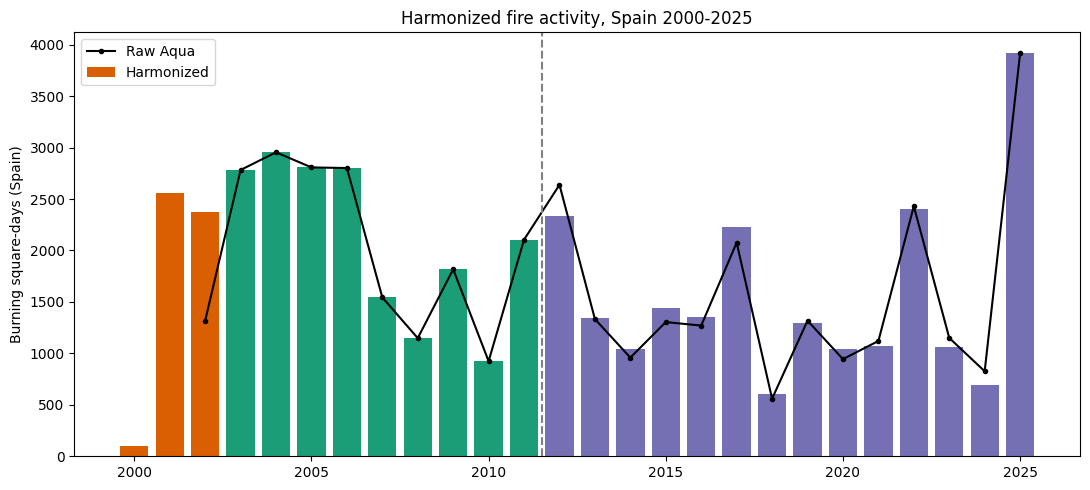

In [71]:
import matplotlib.pyplot as plt

y = out.groupby("year").agg(h=("count_harmonized", "sum"),
                            aqua=("count_aqua_raw", "sum"))
src = out.groupby("year")["source"].agg(lambda s: s.value_counts().idxmax())
colors = src.map({"Terra_scaled": "#d95f02", "Aqua": "#1b9e77", "VIIRS_scaled": "#7570b3"})

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(y.index, y["h"], color=colors, label="Harmonized")
ax.plot(y.index[y.aqua > 0], y["aqua"][y.aqua > 0], "k.-", label="Raw Aqua")
ax.axvline(2011.5, color="gray", ls="--")
ax.set_ylabel("Burning square-days (Spain)")
ax.set_title("Harmonized fire activity, Spain 2000-2025")
ax.legend()
plt.tight_layout()
plt.show()

In [72]:
fig.savefig(f"{data}/harmonized/harmonized_yearly_plot.png", dpi=200)

In [73]:
# one row for every province on every day, so quiet days show as zero
days = pd.date_range("2000-11-01", "2025-12-31", freq="D")
grid = pd.MultiIndex.from_product([provs, days], names=["province", "date"])

def daily(df_, name):
    return df_.groupby(["province", "date"]).size().rename(name)

dd = (pd.DataFrame(index=grid)
        .join([daily(cells[cells["satellite"] == "Terra"], "count_terra_raw"),
               daily(cells[cells["satellite"] == "Aqua"], "count_aqua_raw"),
               daily(viirs6, "count_viirs_raw")])
        .fillna(0))

# same handover rules as the monthly file
dates = dd.index.get_level_values("date")
terra_period = dates <= "2002-07-31"
aqua_period = (dates > "2002-07-31") & (dates <= "2011-12-31")

dd["count_harmonized"] = np.select(
    [terra_period, aqua_period],
    [dd["count_terra_raw"] * k_terra, dd["count_aqua_raw"]],
    default=dd["count_viirs_raw"] * k_viirs).round(2)

dd["source"] = np.select([terra_period, aqua_period],
                         ["Terra_scaled", "Aqua"], default="VIIRS_scaled")

dd = dd.reset_index()
for c in ["count_terra_raw", "count_aqua_raw", "count_viirs_raw"]:
    dd[c] = dd[c].astype(int)

dd.to_parquet(f"{data}/harmonized/harmonized_daily_by_province.parquet", index=False)

print(dd.shape)
yearly_check = dd.groupby(dd["date"].dt.year)["count_harmonized"].sum().round(0)
print(yearly_check.loc[[2003, 2012, 2022, 2025]])

(477984, 7)
date
2003    2782.0
2012    2333.0
2022    2399.0
2025    3923.0
Name: count_harmonized, dtype: float64
